# 01 — Veri kalitesi, eksik veri ekleme ve doldurma (MVI)

**Sahibi:** Öğrenci 1 · **Rubrik:** Data Quality, Advanced MVI & Preprocessing (20 puan)

| Bölüm | İçerik | Çıktı |
|---|---|---|
| 1 | Kısıtların doğrulanması | — |
| 2 | Duplicate, geçerlilik, aykırı değer | `reports/outliers.csv` |
| 3 | %8 eksik veri ekleme (MCAR + MAR) | `reports/constraints.csv`, **Grafik 1** |
| 4 | Sabit train/val/test bölmesi | — |
| 5 | MVI karşılaştırması: median/mode vs KNN vs MICE | `reports/mvi_comparison.csv` |
| 6 | Encoding + ölçekleme, sızıntı kontrolü | `data/processed/clean_*.parquet`, `nan_mask.parquet` |

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
import time

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import to_rgb

from src.config import (
    BILL_COLS, CAT_COLS, FEATURES, ID_COL, PAY_AMT_COLS, PROCESSED_DIR, REPORTS_DIR, SEED,
    SPLITS, TARGET,
)
from src.data import load_raw, load_split, load_splits
from src.features import make_preprocessor
from src.missing import (
    MAR_AGE_COLS, MAR_LIMIT_COLS, PROTECTED_COLS, Imputer, apply_mask, imputation_errors,
    inject_missing,
)
from src.plots import DIVERGING, INK_MUTED, SERIES, save_fig, set_style
from src.quality import (
    constraint_report, duplicate_report, fix_invalid_codes, iqr_outliers, signed_log1p,
    validity_report,
)
from src.utility import lgbm_utility

set_style()
pd.set_option("display.float_format", "{:.4f}".format)
REPORTS_DIR.mkdir(exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

## 1. Veri seti ve kısıtlar

**İş problemi:** Tayvan'da bir bankanın 30.000 kredi kartı müşterisi. Hedef, müşterinin
bir sonraki ay temerrüde düşüp düşmeyeceği (`default` = 1). Kaçırılan bir temerrüt (FN)
doğrudan kredi kaybıdır; yanlış alarm (FP) ise iyi bir müşteriyi kaybettirir. Bu yüzden
accuracy değil, iki sınıfı da dengeli ölçen **Macro-F1** ve **PR-AUC** ana metriklerimiz.

In [3]:
raw_all = load_raw(drop_duplicates=False)
df = load_raw()
print(f"Ham satır: {len(raw_all):,}  |  duplicate atıldıktan sonra: {len(df):,}")
print("Sınıf dağılımı:", df[TARGET].value_counts().to_dict())
constraint_report(df)

Ham satır: 30,000  |  duplicate atıldıktan sonra: 29,965
Sınıf dağılımı: {0: 23335, 1: 6630}


,constraint,required,value,ok
0,Rows,">= 20,000","29,965",True
1,Features,>= 20,23,True
2,Categorical share,>= 30%,39.1% (9/23),True
3,Missing cells,>= 5%,0.00%,False
4,Imbalance (majority:minority),>= 3:1,3.52:1,True


Veri doğal olarak **eksiksiz**, bu yüzden "Missing cells" satırı şu an `False`.
Bölüm 3'te kontrollü olarak %8 eksik veri ekleyeceğiz. Gerçek değerleri bildiğimiz için
doldurma yöntemlerinin hatasını doğrudan ölçebileceğiz.

## 2. Veri kalitesi

### 2.1 Duplicate satırlar

In [4]:
print(duplicate_report(raw_all))
dup_rows = raw_all[raw_all.duplicated(subset=FEATURES + [TARGET], keep=False)]
dup_rows.sort_values(FEATURES).head(6)

{'exact_duplicate_rows': 35, 'feature_duplicates_with_conflicting_target': 21}


,row_id,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
12430,12430,20000,1,2,2,24,2,2,4,4,...,1650,1650,1650,0,0,0,0,0,0,1
14294,14294,20000,1,2,2,24,2,2,4,4,...,1650,1650,1650,0,0,0,0,0,0,1
1759,1759,50000,1,2,2,26,1,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
10250,10250,50000,1,2,2,26,1,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
7170,7170,50000,2,1,2,23,1,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
17032,17032,50000,2,1,2,23,1,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0


- **35 birebir tekrar:** tüm özellikleri **ve** hedefi aynı olan satırlar. İlki tutulup
  diğerleri atılır (`load_raw()` bunu varsayılan yapar; sabit bölme de bu temiz veriden
  üretildi). Görüldüğü gibi çoğu, kartı hiç kullanmamış (tüm tutarlar 0) müşteriler.
- **21 "çelişkili" grup:** özellikleri birebir aynı ama biri temerrüde düşmüş, diğeri
  düşmemiş. Bunlar hata değil, gerçek gözlemler; atılmaz. Ama bize şunu söyler: bu 23
  özellik temerrüdü tam olarak belirlemiyor, hiçbir model %100 doğruluğa ulaşamaz.

### 2.2 Geçerlilik kontrolleri

In [5]:
display(validity_report(df))
df_clean, changed = fix_invalid_codes(df)
print("'other' koduna taşınan satırlar:", changed)
pd.concat(
    {
        "EDUCATION (sonra)": df_clean["EDUCATION"].value_counts().sort_index(),
        "MARRIAGE (sonra)": df_clean["MARRIAGE"].value_counts().sort_index(),
    },
    axis=1,
).fillna(0).astype(int)

,check,rows,share
0,LIMIT_BAL <= 0,0,0.0000
1,AGE outside 18-100,0,0.0000
2,"SEX not in {1,2}",0,0.0000
3,"EDUCATION in {0,5,6} (undocumented)",345,0.0115
4,MARRIAGE == 0 (undocumented),54,0.0018
5,PAY_x outside -2..8,0,0.0000
6,PAY_AMT negative,0,0.0000
7,BILL_AMT negative (valid: credit balance),1930,0.0644


'other' koduna taşınan satırlar: {'EDUCATION': 345, 'MARRIAGE': 54}


,EDUCATION (sonra),MARRIAGE (sonra)
1,10563,13643
2,14019,15945
3,4915,377
4,468,0


- **EDUCATION** dokümanda 1=lisansüstü, 2=üniversite, 3=lise, 4=diğer. 0, 5 ve 6 kodları
  tanımsız → 4'e (diğer) taşındı.
- **MARRIAGE** 1=evli, 2=bekâr, 3=diğer. 0 kodu tanımsız → 3'e taşındı.
- **PAY_x** (ödeme durumu): −2 = kart kullanılmadı, −1 = tam ödendi, 0 = asgari ödeme
  (revolving kredi), 1…8 = kaç ay gecikme olduğu. Sayısal görünse de bir **durum kodu**
  olduğundan kategorik sayıyoruz.
- **Negatif BILL_AMT** hata değil: müşteri fazla ödeme yapmış, alacak bakiyesi var. Korunur.

PAY_0 (son ayın ödeme durumu) ile temerrüt oranı arasındaki ilişki, bu kodların neden
önemli olduğunu gösteriyor:

In [6]:
df_clean.groupby("PAY_0")[TARGET].agg(rows="size", default_rate="mean")

,rows,default_rate
PAY_0,,
-2,2750,0.1324
-1,5682,0.1679
0,14737,0.1281
1,3667,0.3403
2,2666,0.6913
3,322,0.7578
4,76,0.6842
5,26,0.5000
6,11,0.5455


### 2.3 Aykırı değerler (IQR yöntemi)

In [7]:
outliers = iqr_outliers(df_clean)
outliers.to_csv(REPORTS_DIR / "outliers.csv")
outliers

,q1,q3,lower,upper,n_outliers,pct_outliers,max
PAY_AMT4,300.0000,4016.0000,-5274.0000,9590.0000,2993,9.9900,621000
PAY_AMT6,131.0000,4000.0000,-5672.5000,9803.5000,2960,9.8800,528666
PAY_AMT5,261.0000,4042.0000,-5410.5000,9713.5000,2944,9.8200,426529
PAY_AMT1,1000.0000,5008.0000,-5012.0000,11020.0000,2742,9.1500,873552
PAY_AMT2,850.0000,5000.0000,-5375.0000,11225.0000,2723,9.0900,1684259
BILL_AMT5,1787.0000,50247.0000,-70903.0000,122937.0000,2724,9.0900,927171
BILL_AMT6,1262.0000,49252.0000,-70723.0000,121237.0000,2688,8.9700,961664
BILL_AMT4,2360.0000,54601.0000,-76001.5000,132962.5000,2616,8.7300,891586
PAY_AMT3,390.0000,4512.0000,-5793.0000,10695.0000,2596,8.6600,896040
BILL_AMT3,2711.0000,60201.0000,-83524.0000,146436.0000,2469,8.2400,1664089


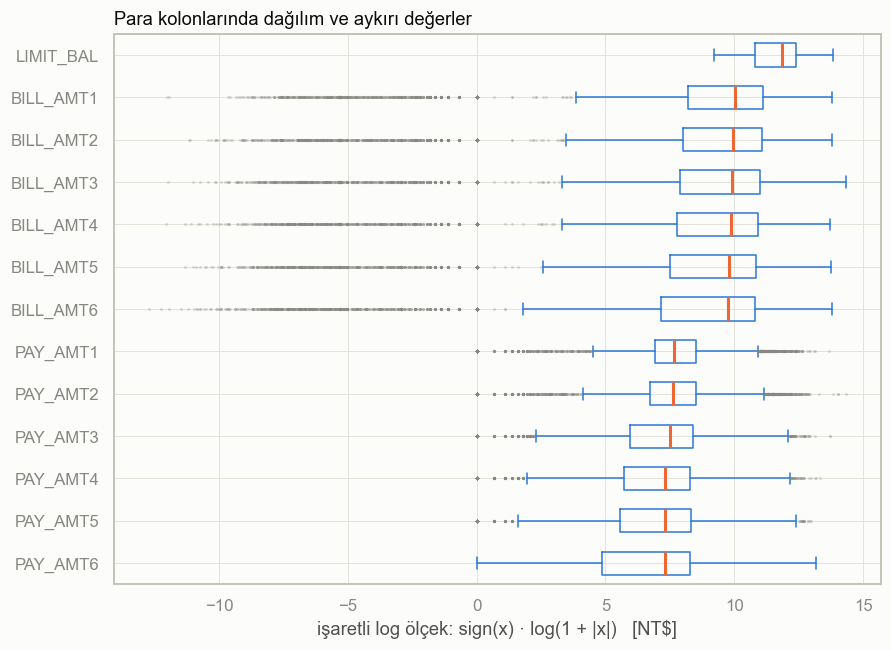

In [8]:
money = ["LIMIT_BAL"] + BILL_COLS + PAY_AMT_COLS
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.boxplot(
    [signed_log1p(df_clean[c]) for c in money],
    vert=False,
    widths=0.55,
    flierprops=dict(marker=".", markersize=2, alpha=0.25, markeredgecolor=INK_MUTED),
    medianprops=dict(color=SERIES[1], linewidth=2),
    boxprops=dict(color=SERIES[0]),
    whiskerprops=dict(color=SERIES[0]),
    capprops=dict(color=SERIES[0]),
)
ax.set_yticks(range(1, len(money) + 1), money)
ax.invert_yaxis()
ax.set_xlabel("işaretli log ölçek: sign(x) · log(1 + |x|)   [NT$]")
ax.set_title("Para kolonlarında dağılım ve aykırı değerler", loc="left")
save_fig(fig, "extra_outliers_boxplot")
plt.show()

**Karar: aykırı değerler silinmiyor.** Para kolonlarında %7–10 oranında IQR dışı değer
var, ama bunlar ölçüm hatası değil, yüksek limitli/yüksek harcamalı gerçek müşteriler.
Silmek, tam da riskli olabilecek bir müşteri kesimini veri setinden çıkarmak olurdu.
Bunun yerine:
- Lineer model ve TabNet için **RobustScaler** (medyan ve IQR ile ölçekler; uç değerler
  ölçeği bozmaz),
- LightGBM için ölçekleme gerekmez (ağaçlar sıralamaya bakar, aykırı değere duyarsızdır).

## 3. %8 eksik veri ekleme

| Mekanizma | Pay | Nasıl |
|---|---|---|
| **MCAR** | ~%5 | 20 kolonda her hücre aynı olasılıkla silinir |
| **MAR** | ~%3 | `BILL_AMT2-6` yaşlı müşterilerde, `PAY_AMT2-6` düşük limitli müşterilerde daha çok eksik |
| Korunan | — | `LIMIT_BAL`, `AGE`, `PAY_0` hiç silinmez: MAR'ın "gözlenen" sürücüleri bunlar |

Maske `SEED` ile tüm veriye bir kez uygulanır (maske öğrenilen bir şey olmadığı için
sızıntı yaratmaz). Doldurma yöntemleri ise **yalnızca train'e** fit edilecek.

In [9]:
mask = inject_missing(df_clean, mcar_rate=0.05, mar_rate=0.03, seed=SEED)
holed = apply_mask(df_clean, mask)
print(f"Toplam eksik hücre oranı: {mask.to_numpy().mean():.2%}")

mechanism = np.select(
    [mask.columns.isin(PROTECTED_COLS), mask.columns.isin(MAR_AGE_COLS),
     mask.columns.isin(MAR_LIMIT_COLS)],
    ["korunuyor", "MCAR + MAR(AGE)", "MCAR + MAR(LIMIT_BAL)"],
    default="MCAR",
)
pd.DataFrame({"missing_rate": mask.mean(), "mechanism": mechanism}).T

Toplam eksik hücre oranı: 7.96%


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
missing_rate,0.0000,0.0576,0.0577,0.0563,0.0000,0.0000,0.0570,0.0572,0.0561,0.0554,...,0.1270,0.1223,0.1300,0.1235,0.0567,0.1281,0.1275,0.1251,0.1261,0.1264
mechanism,korunuyor,MCAR,MCAR,MCAR,korunuyor,korunuyor,MCAR,MCAR,MCAR,MCAR,...,MCAR + MAR(AGE),MCAR + MAR(AGE),MCAR + MAR(AGE),MCAR + MAR(AGE),MCAR,MCAR + MAR(LIMIT_BAL),MCAR + MAR(LIMIT_BAL),MCAR + MAR(LIMIT_BAL),MCAR + MAR(LIMIT_BAL),MCAR + MAR(LIMIT_BAL)


In [10]:
age_band = pd.cut(df_clean["AGE"], [20, 30, 40, 50, 80], labels=["21-30", "31-40", "41-50", "51+"])
limit_band = pd.qcut(df_clean["LIMIT_BAL"], 4, labels=["Q1 düşük", "Q2", "Q3", "Q4 yüksek"])
display(mask[MAR_AGE_COLS].mean(axis=1).groupby(age_band, observed=True).mean()
        .rename("BILL_AMT2-6 eksik oranı").to_frame().T)
display(mask[MAR_LIMIT_COLS].mean(axis=1).groupby(limit_band, observed=True).mean()
        .rename("PAY_AMT2-6 eksik oranı").to_frame().T)

AGE,21-30,31-40,41-50,51+
BILL_AMT2-6 eksik oranı,0.0761,0.1287,0.1821,0.2017


LIMIT_BAL,Q1 düşük,Q2,Q3,Q4 yüksek
PAY_AMT2-6 eksik oranı,0.1875,0.1451,0.0957,0.0740


MAR mekanizması beklendiği gibi çalışıyor. Şimdi kısıt tablosunun son halini kaydediyoruz:

In [11]:
constraints = constraint_report(holed)
constraints.to_csv(REPORTS_DIR / "constraints.csv", index=False)
constraints

,constraint,required,value,ok
0,Rows,">= 20,000","29,965",True
1,Features,>= 20,23,True
2,Categorical share,>= 30%,39.1% (9/23),True
3,Missing cells,>= 5%,7.96%,True
4,Imbalance (majority:minority),>= 3:1,3.52:1,True


### Grafik 1 — Eksiklik örüntüleri

(a) Matriste satırlar **yaşa göre sıralı** (aşağı = yaşlı). MAR etkisi `BILL_AMT2-6`
kolonlarında aşağı doğru artan yoğunluk olarak görünür.
(b) Eksiklik korelasyonu: iki kolonun aynı satırda birlikte eksik olma eğilimi.
(c) Dendrogram: eksiklik örüntüsü benzer olan kolonları gruplar.

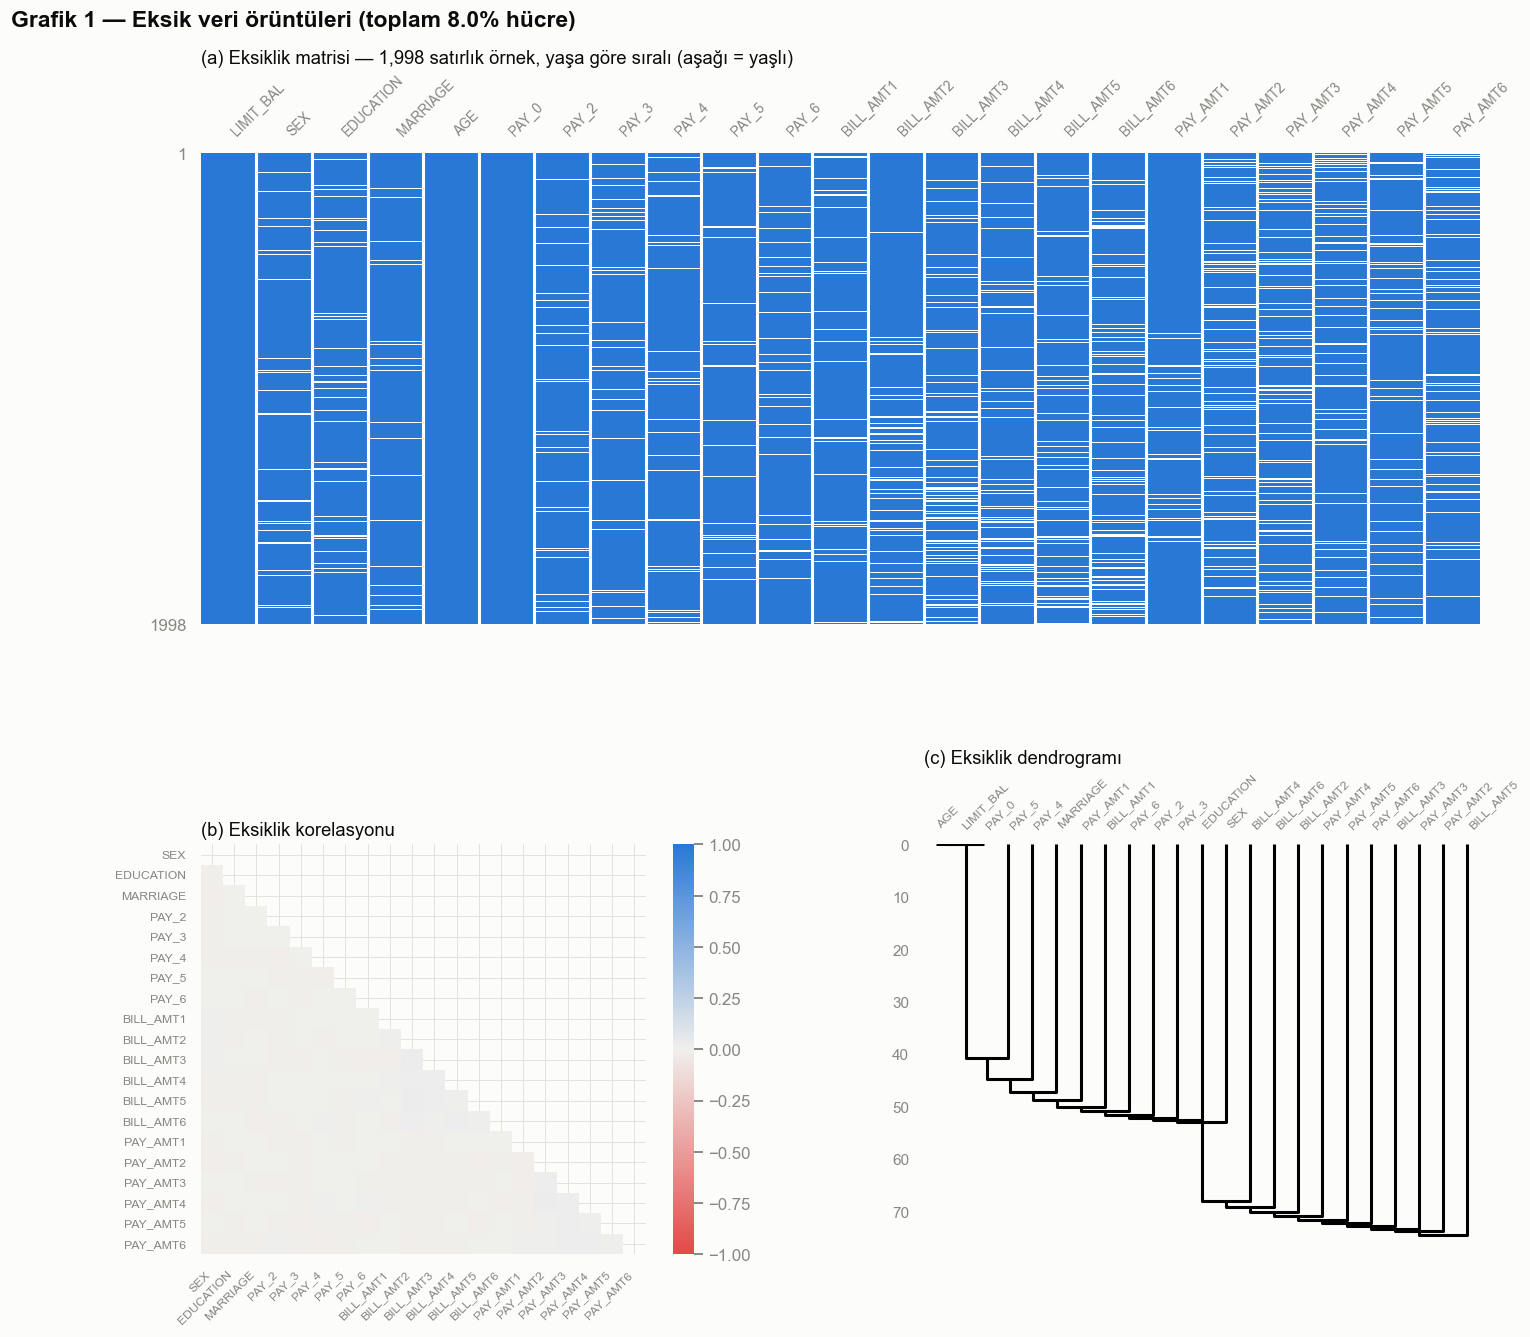

In [12]:
null_view = holed[FEATURES]
by_age = null_view.loc[df_clean.sort_values("AGE", kind="stable").index].iloc[::15]

fig = plt.figure(figsize=(15, 13))
grid = fig.add_gridspec(2, 2, height_ratios=[1.15, 1], hspace=0.5, wspace=0.3)
ax_m, ax_h, ax_d = fig.add_subplot(grid[0, :]), fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])

msno.matrix(by_age, ax=ax_m, sparkline=False, fontsize=9, color=to_rgb(SERIES[0]))
ax_m.set_title(f"(a) Eksiklik matrisi — {len(by_age):,} satırlık örnek, yaşa göre sıralı (aşağı = yaşlı)",
               loc="left", fontsize=12)
msno.heatmap(null_view, ax=ax_h, fontsize=8, cmap=DIVERGING)
ax_h.set_title("(b) Eksiklik korelasyonu", loc="left", fontsize=12)
msno.dendrogram(null_view, ax=ax_d, fontsize=8)
ax_d.set_title("(c) Eksiklik dendrogramı", loc="left", fontsize=12)
fig.suptitle(f"Grafik 1 — Eksik veri örüntüleri (toplam {mask.to_numpy().mean():.1%} hücre)",
             x=0.01, ha="left", fontsize=15, fontweight="bold")
save_fig(fig, "fig1_missingness")
plt.show()

**Okuma:** (a)'da `BILL_AMT2-6` kolonları aşağıya (yaşlı müşterilere) doğru belirgin
şekilde seyreliyor, yani MAR etkisi görünüyor. (b)'deki korelasyonların sıfıra yakın olması
beklenen bir sonuç: hücreleri kolonlar arasında bağımsız sildik, "bir kolon eksikse
diğeri de eksik" türü blok eksiklik yok. (c)'de hiç eksik olmayan üç kolon (`AGE`,
`LIMIT_BAL`, `PAY_0`) ayrı bir küme oluşturuyor.

## 4. Sabit bölme (`data/splits.csv`)

In [13]:
split_of = df_clean[ID_COL].map(load_splits().set_index(ID_COL)["split"])
assert split_of.notna().all(), "her satırın bir split'i olmalı"

truth = {s: df_clean[split_of == s].reset_index(drop=True) for s in SPLITS}
holes = {s: holed[split_of == s].reset_index(drop=True) for s in SPLITS}
masks = {s: mask[split_of == s].reset_index(drop=True) for s in SPLITS}
pd.DataFrame(
    {s: {"rows": len(truth[s]), "default_rate": truth[s][TARGET].mean(),
         "missing_rate": masks[s].to_numpy().mean()} for s in SPLITS}
).T.astype({"rows": int})

,rows,default_rate,missing_rate
train,20975,0.2213,0.0794
val,4495,0.2211,0.0795
test,4495,0.2214,0.0801


## 5. MVI karşılaştırması

Her yöntem **train'e fit edilir**, train ve val'e uygulanır. Üç eksende ölçüyoruz:

1. **Doldurma hatası (val):** maskelenen hücrelerde sayısal kolonlar için
   NRMSE = RMSE / kolonun std'si (kolonlar arası karşılaştırılabilir), kategorikler için
   doğru kodu bulma oranı.
2. **Model faydası:** sabit parametreli LightGBM doldurulmuş train'de eğitilir, doldurulmuş
   val'de ölçülür (`src/utility.py`). Referans satırı: hiç eksik olmasaydı.
3. **Süre.**

KNN, uzaklık hesabı kolonların ölçeğinden etkilendiği için önce RobustScaler ile
ölçeklenmiş veride çalışır, sonra değerler geri dönüştürülür. KNN ve MICE kategorik
kolonlarda ondalıklı değer üretebileceği için sonuçlar en yakın geçerli koda yuvarlanır.

In [14]:
candidates = {
    "median_mode (baseline)": Imputer("median_mode"),
    "knn (k=5)": Imputer("knn", n_neighbors=5),
    "knn (k=10)": Imputer("knn", n_neighbors=10),
    "mice (BayesianRidge)": Imputer("mice", max_iter=10),
}

def with_target(features, split):
    return features.assign(**{TARGET: truth[split][TARGET].to_numpy()})

rows, errors_by_method, val_filled_by_method = [], {}, {}
for name, imputer in candidates.items():
    start = time.perf_counter()
    imputer.fit(holes["train"])
    train_filled = imputer.transform(holes["train"])
    val_filled = imputer.transform(holes["val"])
    seconds = time.perf_counter() - start

    errors = imputation_errors(truth["val"], val_filled, masks["val"])
    utility = lgbm_utility(with_target(train_filled, "train"), with_target(val_filled, "val"))
    errors_by_method[name], val_filled_by_method[name] = errors, val_filled
    rows.append({
        "method": name,
        "mean_nrmse": errors.loc[errors["kind"] == "numeric", "nrmse"].mean(),
        "cat_accuracy": errors.loc[errors["kind"] == "categorical", "accuracy"].mean(),
        **{f"val_{k}": v for k, v in utility.items() if k != "accuracy"},
        "seconds": seconds,
    })
    print(f"{name:24s} {seconds:6.1f} s")

oracle = lgbm_utility(truth["train"], truth["val"])
rows.append({"method": "referans: eksiksiz veri", "mean_nrmse": 0.0, "cat_accuracy": 1.0,
             **{f"val_{k}": v for k, v in oracle.items() if k != "accuracy"}, "seconds": 0.0})
mvi = pd.DataFrame(rows).set_index("method")
mvi.to_csv(REPORTS_DIR / "mvi_comparison.csv")
mvi

median_mode (baseline)      0.1 s


knn (k=5)                  25.1 s


knn (k=10)                 25.2 s


mice (BayesianRidge)        3.5 s


,mean_nrmse,cat_accuracy,val_macro_f1,val_weighted_f1,val_roc_auc,val_pr_auc,seconds
method,,,,,,,
median_mode (baseline),0.9521,0.5290,0.7053,0.7971,0.7730,0.5444,0.0517
knn (k=5),0.5554,0.7288,0.7073,0.8067,0.7769,0.5487,25.1417
knn (k=10),0.5562,0.7110,0.7041,0.8029,0.7729,0.5419,25.1962
mice (BayesianRidge),0.4461,0.7018,0.7058,0.8057,0.7712,0.5430,3.4632
referans: eksiksiz veri,0.0000,1.0000,0.7085,0.8042,0.7722,0.5490,0.0000


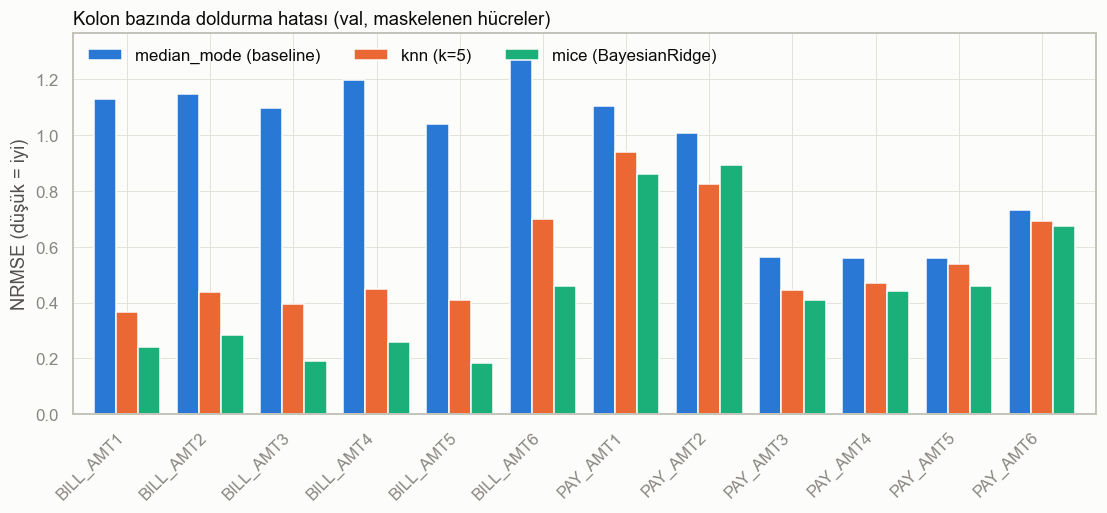

In [15]:
nrmse = pd.DataFrame({name: e.set_index("column")["nrmse"] for name, e in errors_by_method.items()}).dropna()
shown = ["median_mode (baseline)", "knn (k=5)", "mice (BayesianRidge)"]
ax = nrmse[shown].plot.bar(figsize=(12, 4.5), width=0.8, color=SERIES, edgecolor="#fcfcfb", linewidth=1)
ax.set_ylabel("NRMSE (düşük = iyi)")
ax.set_xlabel("")
ax.set_title("Kolon bazında doldurma hatası (val, maskelenen hücreler)", loc="left")
ax.legend(ncols=3, loc="upper left")
plt.xticks(rotation=45, ha="right")
save_fig(ax.figure, "extra_mvi_nrmse")
plt.show()

**Dağılım koruması.** Median doldurma tüm eksik hücrelere aynı değeri yazar ve dağılımda
yapay bir tepe oluşturur. İleri yöntemler gerçek dağılıma (gri) ne kadar yakın kalıyor?

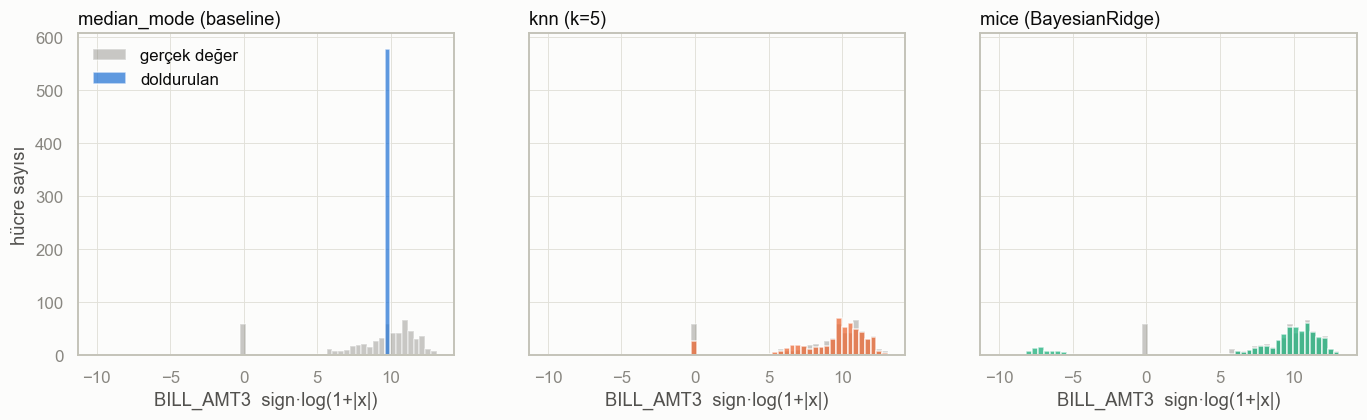

In [16]:
col = "BILL_AMT3"
hit = masks["val"][col].to_numpy()
true_vals = signed_log1p(truth["val"].loc[hit, col])
filled_vals = {name: signed_log1p(val_filled_by_method[name].loc[hit, col]) for name in shown}
# One set of bin edges for every series, so a constant fill (median) shows as a spike.
everything = np.concatenate([true_vals, *filled_vals.values()])
bins = np.linspace(everything.min(), everything.max(), 60)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, name, color in zip(axes, shown, SERIES):
    ax.hist(true_vals, bins=bins, color=INK_MUTED, alpha=0.45, label="gerçek değer")
    ax.hist(filled_vals[name], bins=bins, color=color, alpha=0.75, label="doldurulan")
    ax.set_title(name, loc="left")
    ax.set_xlabel(f"{col}  sign·log(1+|x|)")
axes[0].legend(loc="upper left")
axes[0].set_ylabel("hücre sayısı")
save_fig(fig, "extra_mvi_distribution")
plt.show()

**Yöntem seçimi.** Üç kriterde (NRMSE ↓, kategorik doğruluk ↑, val PR-AUC ↑) her yöntemin
sırası alınır; ortalama sırası en iyi olan seçilir. Tek bir metriğe bakmak yerine hem
doldurma kalitesini hem de modele faydasını dengeliyoruz.

In [17]:
methods = mvi.drop(index="referans: eksiksiz veri")
ranks = pd.DataFrame({
    "nrmse": methods["mean_nrmse"].rank(),
    "cat_accuracy": methods["cat_accuracy"].rank(ascending=False),
    "val_pr_auc": methods["val_pr_auc"].rank(ascending=False),
})
ranks["mean_rank"] = ranks.mean(axis=1)
BEST = ranks["mean_rank"].idxmin()
display(ranks.sort_values("mean_rank"))
print("Seçilen yöntem:", BEST)

,nrmse,cat_accuracy,val_pr_auc,mean_rank
method,,,,
knn (k=5),2.0000,1.0000,1.0000,1.3333
mice (BayesianRidge),1.0000,3.0000,3.0000,2.3333
knn (k=10),3.0000,2.0000,4.0000,3.0000
median_mode (baseline),4.0000,4.0000,2.0000,3.3333


Seçilen yöntem: knn (k=5)


**Yorum**

- **Baseline'ın NRMSE'si ≈ 0,95:** her eksik hücreye medyanı yazmak, kolonun ortalamasını
  tahmin etmekten pek farklı değil (NRMSE = 1 o seviye). İki ileri yöntem de hatayı
  neredeyse yarıya indiriyor.
- **MICE** sayısal kolonlarda en düşük hatayı veriyor (BILL_AMT'ler birbiriyle çok güçlü
  korele, regresyon bunu yakalıyor). Ama dağılım grafiğinde görüldüğü gibi doğrusal
  model gerçekte hiç olmayan negatif değerler de üretebiliyor. Kategoriklerde de KNN'in
  gerisinde kalıyor.
- **KNN (k=5)** kategorik kodları en iyi geri getiren yöntem ve model faydası eksiksiz
  verideki referansla neredeyse aynı. Seçilen yöntem bu.
- Model faydası farkları küçük (PR-AUC 0,542–0,549). LightGBM %8 eksikliğe karşı zaten
  dayanıklı. İleri MVI'nin asıl kazancı verinin kendisinin doğru kalması: sentetik veri
  üretimi ve lineer model bu değerleri doğrudan kullanacak.

## 6. Clean veri, encoding ve ölçekleme

Seçilen imputer (train'e fit edilmiş halde) üç split'e uygulanır. Sözleşmeye göre
`clean_*.parquet` dosyaları **ölçeklenmemiş** ve kategorikleri tam sayı kod olarak tutar;
her model kendi ön işleyicisini (`src/features.py`) **kendi train setine** fit eder.

In [18]:
best = candidates[BEST]
clean = {}
for s in SPLITS:
    filled = best.transform(holes[s]).round().astype("int64")
    clean[s] = pd.concat([holes[s][[ID_COL]], filled, holes[s][[TARGET]]], axis=1)
    assert not clean[s].isna().any().any()
    assert clean[s][ID_COL].equals(truth[s][ID_COL])
{s: clean[s].shape for s in SPLITS}

{'train': (20975, 25), 'val': (4495, 25), 'test': (4495, 25)}

In [19]:
pre = make_preprocessor("linear").fit(clean["train"][FEATURES])
print({s: pre.transform(clean[s][FEATURES]).shape for s in SPLITS})
scaler = pre.named_transformers_["scale"]
pd.DataFrame(
    {"center = train medyanı": scaler.center_, "scale = train IQR": scaler.scale_},
    index=scaler.feature_names_in_,
).head(8)

{'train': (20975, 33), 'val': (4495, 33), 'test': (4495, 33)}


,center = train medyanı,scale = train IQR
LIMIT_BAL,140000.0000,190000.0000
AGE,34.0000,13.0000
BILL_AMT1,23043.0000,64124.5000
BILL_AMT2,22161.0000,60701.5000
BILL_AMT3,20558.0000,57305.0000
BILL_AMT4,19330.0000,52296.5000
BILL_AMT5,18372.0000,48515.5000
BILL_AMT6,17427.0000,48034.0000


**Neden veri sızıntısı yok?**

1. Bölme her şeyden önce yapıldı ve `data/splits.csv` ile sabitlendi.
2. Imputer'ın medyan/komşu/regresyon istatistikleri **yalnızca train**'den öğrenildi;
   val ve test sadece `transform` gördü.
3. RobustScaler'ın medyan ve IQR'ı yukarıda görüldüğü gibi train'den geliyor.
4. Sentetik veri (notebook 02) yalnızca `clean_train` üzerinden üretilecek; val ve test
   hiçbir üreticiye gösterilmeyecek.

In [20]:
for s in SPLITS:
    clean[s].to_parquet(PROCESSED_DIR / f"clean_{s}.parquet", index=False)
pd.concat([df_clean[[ID_COL]], mask], axis=1).to_parquet(PROCESSED_DIR / "nan_mask.parquet", index=False)

roundtrip = load_split("train", "clean")
assert roundtrip.equals(clean["train"])
sorted((p.name, f"{p.stat().st_size / 1e6:.2f} MB") for p in PROCESSED_DIR.glob("*.parquet"))

[('clean_test.parquet', '0.30 MB'),
 ('clean_train.parquet', '1.27 MB'),
 ('clean_val.parquet', '0.30 MB'),
 ('nan_mask.parquet', '0.25 MB')]

## Özet (checkpoint CP-A)

| Madde | Sonuç |
|---|---|
| Kısıtlar | 29.965 satır · 23 özellik · %39,1 kategorik · %7,96 eksik hücre · 3,52:1 dengesizlik |
| Kalite | 35 duplicate atıldı · 399 tanımsız kod "other"a taşındı · aykırı değerler korunup RobustScaler ile yönetildi |
| Eksiklik | ~%5 MCAR + ~%3 MAR (yaş → BILL_AMT, limit → PAY_AMT) |
| MVI | Baseline'a göre iki ileri yöntem karşılaştırıldı. Seçilen yöntem KNN (k=5) |
| Teslim | `clean_{train,val,test}.parquet` ve `nan_mask.parquet`: Öğrenci 2 ve 3 `variant="clean"` ile kullanabilir |